In [36]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

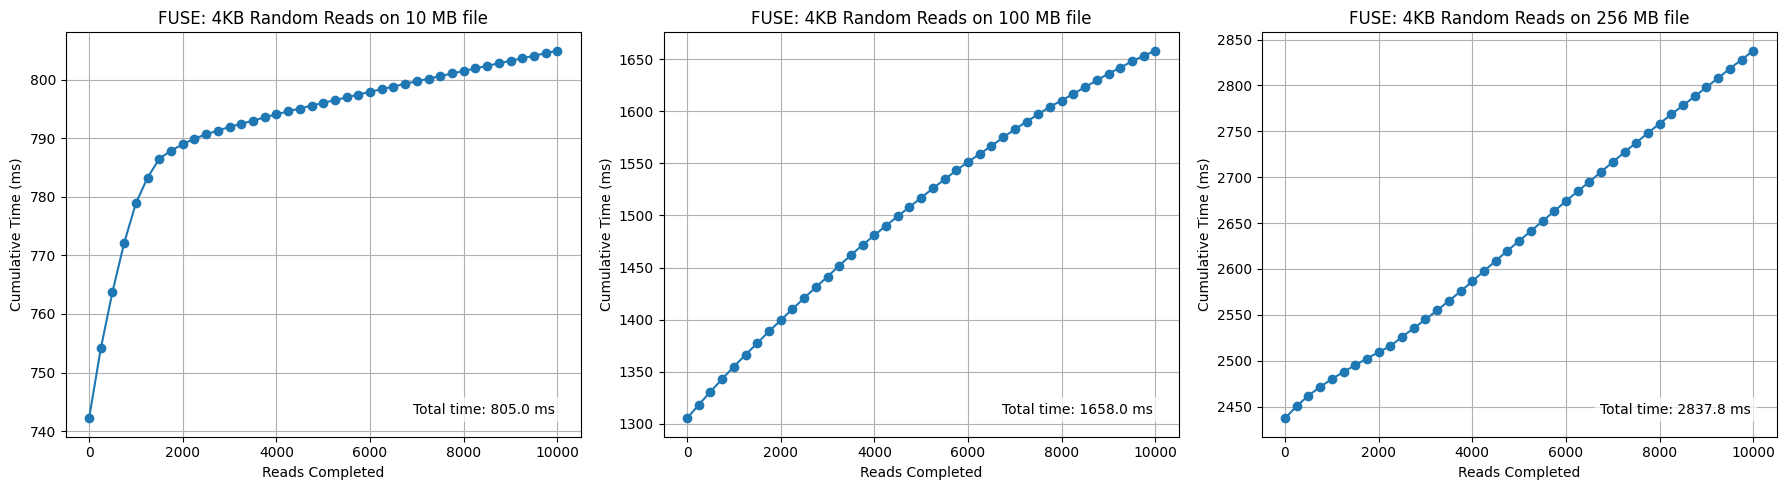

In [37]:
df_10 = pd.read_csv("fuse_read_results_2.csv")     # 10 MB file
df_100 = pd.read_csv("fuse_read_results_1.csv")    # 100 MB file
df_256 = pd.read_csv("fuse_read_results.csv")      # 256 MB file

# Create subplots (1 row, 3 columns)
fig, axes = plt.subplots(1, 3, figsize=(18,5), sharey=False)

# Helper to plot and annotate
def plot_with_final(ax, df, title):
    ax.plot(df["ReadsCompleted"], df["CumulativeTime(ms)"], marker='o')
    ax.set_title(title)
    ax.set_xlabel("Reads Completed")
    ax.set_ylabel("Cumulative Time (ms)")
    ax.grid(True)

    # Get final cumulative time
    final_time = df["CumulativeTime(ms)"].iloc[-1]
    # Annotate in bottom right (axes coordinates: x=0.95, y=0.05)
    ax.text(0.95, 0.05,
            f"Total time: {final_time:.1f} ms",
            transform=ax.transAxes,
            fontsize=10,
            ha='right', va='bottom',
            bbox=dict(facecolor='white', alpha=0.7, edgecolor='none'))

# Plot each graph
plot_with_final(axes[0], df_10, "FUSE: 4KB Random Reads on 10 MB file")
plot_with_final(axes[1], df_100, "FUSE: 4KB Random Reads on 100 MB file")
plot_with_final(axes[2], df_256, "FUSE: 4KB Random Reads on 256 MB file")

plt.tight_layout()
plt.show()

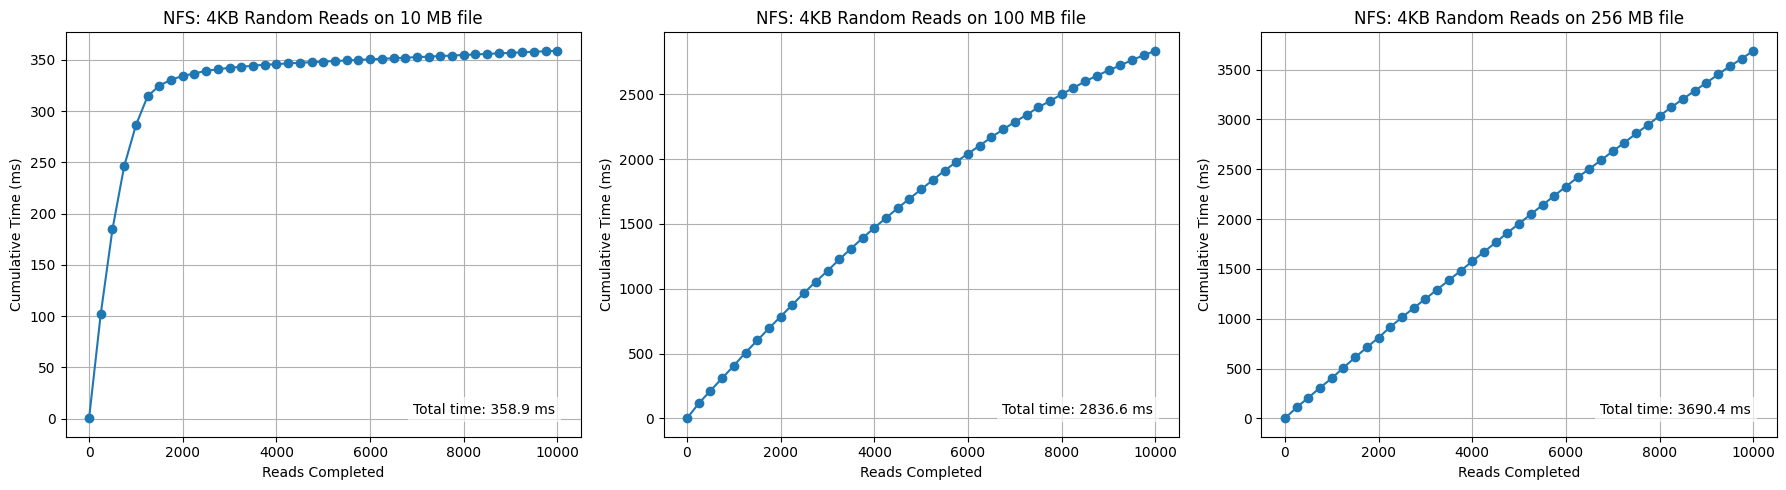

In [38]:
df_10 = pd.read_csv("nfs_read_results_2.csv")     # 10 MB file
df_100 = pd.read_csv("nfs_read_results_1.csv")    # 100 MB file
df_256 = pd.read_csv("nfs_read_results.csv")      # 256 MB file

# Create subplots (1 row, 3 columns)
fig, axes = plt.subplots(1, 3, figsize=(18,5), sharey=False)

# Helper to plot and annotate
def plot_with_final(ax, df, title):
    ax.plot(df["ReadsCompleted"], df["CumulativeTime(ms)"], marker='o')
    ax.set_title(title)
    ax.set_xlabel("Reads Completed")
    ax.set_ylabel("Cumulative Time (ms)")
    ax.grid(True)

    # Get final cumulative time
    final_time = df["CumulativeTime(ms)"].iloc[-1]
    # Annotate in bottom right (axes coordinates: x=0.95, y=0.05)
    ax.text(0.95, 0.05,
            f"Total time: {final_time:.1f} ms",
            transform=ax.transAxes,
            fontsize=10,
            ha='right', va='bottom',
            bbox=dict(facecolor='white', alpha=0.7, edgecolor='none'))

# Plot each graph
plot_with_final(axes[0], df_10, "NFS: 4KB Random Reads on 10 MB file")
plot_with_final(axes[1], df_100, "NFS: 4KB Random Reads on 100 MB file")
plot_with_final(axes[2], df_256, "NFS: 4KB Random Reads on 256 MB file")

plt.tight_layout()
plt.show()

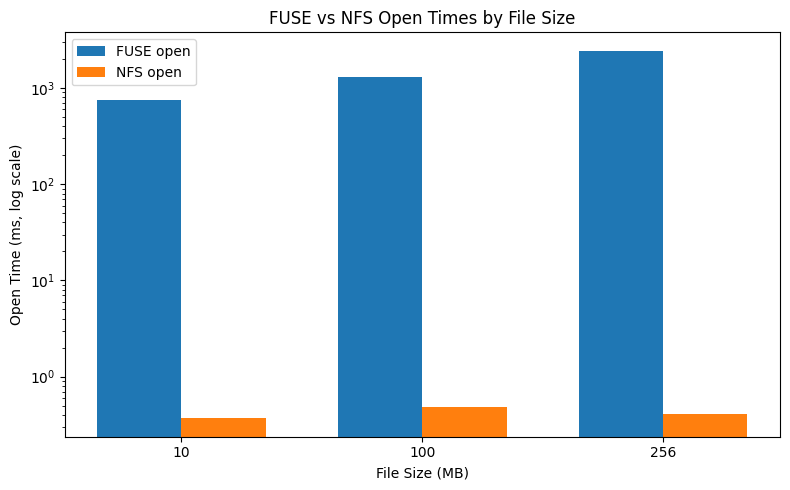

In [ ]:
# Read CSV
df = pd.read_csv("read_open.csv")

# Bar positions
x = np.arange(len(df["FileSize"]))
width = 0.35

fig, ax = plt.subplots(figsize=(8,5))

bars1 = ax.bar(x - width/2, df["FUSEopen"], width, label="FUSE open")
bars2 = ax.bar(x + width/2, df["NFSopen"], width, label="NFS open")

# Labels & formatting
ax.set_xlabel("File Size (MB)")
ax.set_ylabel("Open Time (ms, log scale)")
ax.set_title("FUSE vs NFS Open Times by File Size")
ax.set_xticks(x)
ax.set_xticklabels(df["FileSize"])
ax.set_yscale("log")   # log scale
ax.legend()

plt.tight_layout()
plt.show()
